### 선형 회귀 
 : Auto MPG 데이터 셋 : 특징 7개로 연비를 예측하는 회귀 데이터 셋 <br><br>

- 본 학습에서는 자동차 무게 하나의 입력값으로 연비를 예측하는 선형회귀 만들기 <br>
    'MPG' : 결과, 'weight' : 입력값

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import seaborn as sns 
import torch 
import matplotlib.pyplot as plt 
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import numpy as np 

# 난수 시드 고정 
torch.manual_seed(42)

### Step 1. 데이터 불러오기 및 전처리 

In [3]:
data = sns.load_dataset('mpg')

print(data.head())
print(data.shape)
print('결측치 개수 :', data.isnull().sum())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
(398, 9)
결측치 개수 : mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [4]:
# 자동차의 무게와 연비만 선택 
data = data[['weight','mpg']].dropna()

x = torch.tensor(data[['weight']].values, dtype=torch.float32)
y = torch.tensor(data[['mpg']].values, dtype = torch.float32)

print('입력값 :', x)
print('입력 shape :', x.shape)
print('정답 :', y)
print('정답 shape :', y.shape)

입력값 : tensor([[3504.],
        [3693.],
        [3436.],
        [3433.],
        [3449.],
        [4341.],
        [4354.],
        [4312.],
        [4425.],
        [3850.],
        [3563.],
        [3609.],
        [3761.],
        [3086.],
        [2372.],
        [2833.],
        [2774.],
        [2587.],
        [2130.],
        [1835.],
        [2672.],
        [2430.],
        [2375.],
        [2234.],
        [2648.],
        [4615.],
        [4376.],
        [4382.],
        [4732.],
        [2130.],
        [2264.],
        [2228.],
        [2046.],
        [2634.],
        [3439.],
        [3329.],
        [3302.],
        [3288.],
        [4209.],
        [4464.],
        [4154.],
        [4096.],
        [4955.],
        [4746.],
        [5140.],
        [2962.],
        [2408.],
        [3282.],
        [3139.],
        [2220.],
        [2123.],
        [2074.],
        [2065.],
        [1773.],
        [1613.],
        [1834.],
        [1955.],
        [2278.],
        

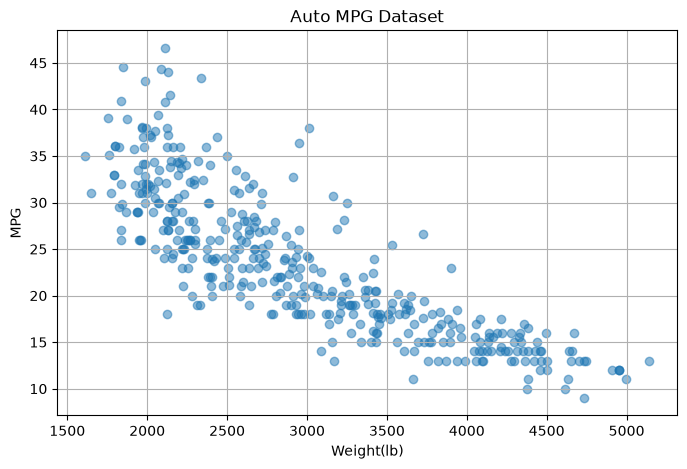

In [5]:
# 그래프 보기
plt.figure(figsize = (8,5))

plt.scatter(x, y, alpha = 0.5)

plt.xlabel('Weight(lb)')
plt.ylabel('MPG')
plt.title('Auto MPG Dataset')
plt.grid(True)

In [6]:
# 학습 데이터와 테스트 데이터 분리(8:2)
indices = torch.randperm(len(x))
train_size = int(len(x) * 0.8)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

x_train = x[train_indices] ## 트레이닝 입력값
x_test = x[test_indices]  ## 테스트 입력값 
y_train = y[train_indices] ## 트레이닝 출력값
y_test = y[test_indices] ## 테스트 출력값

# 데이터 표준화 , 이유 : 데이터끼리 편차가 클 때 평균 0, 표준편차가 1로 정규화 후 학습 
mean = x_train.mean(dim = 0)
std = x_train.std(dim = 0).clamp(min = 1e-8)

x_train_scaled = (x_train - mean) / std
x_test_scaled = (x_test - mean) / std

print('x_train : ', x_train_scaled.shape)
print('y_train : ', y_train.shape)
print('x_test : ', x_test_scaled.shape)
print('y_test : ', y_test.shape)


x_train :  torch.Size([318, 1])
y_train :  torch.Size([318, 1])
x_test :  torch.Size([80, 1])
y_test :  torch.Size([80, 1])


In [7]:
# Dataloader 생성 
BATCH_SIZE = 32

train_DS = TensorDataset(x_train_scaled, y_train)
test_DS = TensorDataset(x_test_scaled, y_test)


train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True) # 섞기 
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = False) # 안섞음 테스트 할때는 안섞어도 된다.

N = len(train_DL.dataset)
print('학습데이터 개수 :', N)

학습데이터 개수 : 318


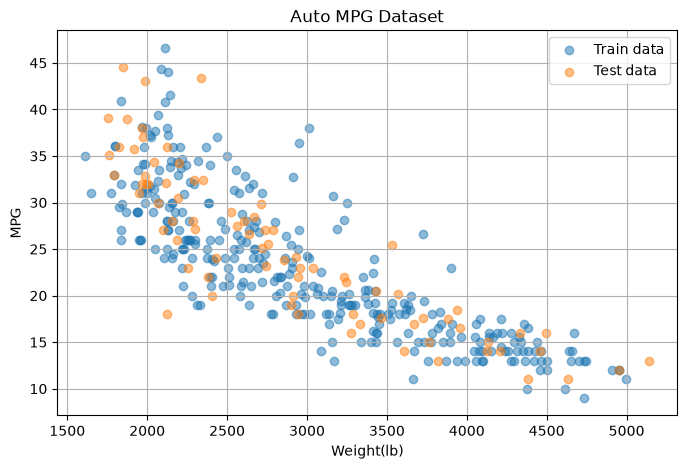

In [8]:
# 그래프로 보기 
plt.figure(figsize = (8,5))

plt.scatter(x_train, y_train, alpha = 0.5, label='Train data')
plt.scatter(x_test, y_test, alpha = 0.5, label='Test data')

plt.xlabel('Weight(lb)')
plt.ylabel('MPG')
plt.title('Auto MPG Dataset')
plt.legend()
plt.grid(True)

### Step 2. 모델 만들기 

In [9]:
model = nn.Linear(1,1)

# 임의의 값으로 데이터 5개 출력 확인
b = model(torch.randn(5,1)) # 개수는 5개 입력값 특징은 1개 

print('출력 shape :', b.shape)
print(b)

출력 shape : torch.Size([5, 1])
tensor([[0.3924],
        [0.4343],
        [0.3408],
        [0.3917],
        [0.3655]], grad_fn=<AddmmBackward0>)


### Step 3. 모델 학습 시키기

In [16]:
LR = 1e-2
EPOCH = 200

optimizer = optim.SGD(model.parameters(), lr = LR)
criterion = nn.MSELoss()

loss_history = []

model.train()
for ep in range(EPOCH) :
    rloss = 0

    for x_batch, y_batch in train_DL : 

        # inference 
        y_hat = model(x_batch)

        # loss
        loss = criterion(y_hat, y_batch)

        # update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item()*x_batch.shape[0]
    
    loss_e = rloss / N
    loss_history.append(loss_e)

    if ep % 10 == 0 : 
        print(f'Epoch : {ep+1}, train loss : {loss_e :.4f}')
        print('-'*20)

Epoch : 1, train loss : 18.6889
--------------------
Epoch : 11, train loss : 18.6905
--------------------
Epoch : 21, train loss : 18.6955
--------------------
Epoch : 31, train loss : 18.6894
--------------------
Epoch : 41, train loss : 18.6874
--------------------
Epoch : 51, train loss : 18.6794
--------------------
Epoch : 61, train loss : 18.6837
--------------------
Epoch : 71, train loss : 18.6944
--------------------
Epoch : 81, train loss : 18.6778
--------------------
Epoch : 91, train loss : 18.6849
--------------------
Epoch : 101, train loss : 18.6819
--------------------
Epoch : 111, train loss : 18.6762
--------------------
Epoch : 121, train loss : 18.6768
--------------------
Epoch : 131, train loss : 18.6794
--------------------
Epoch : 141, train loss : 18.6855
--------------------
Epoch : 151, train loss : 18.6861
--------------------
Epoch : 161, train loss : 18.6786
--------------------
Epoch : 171, train loss : 18.6749
--------------------
Epoch : 181, train lo

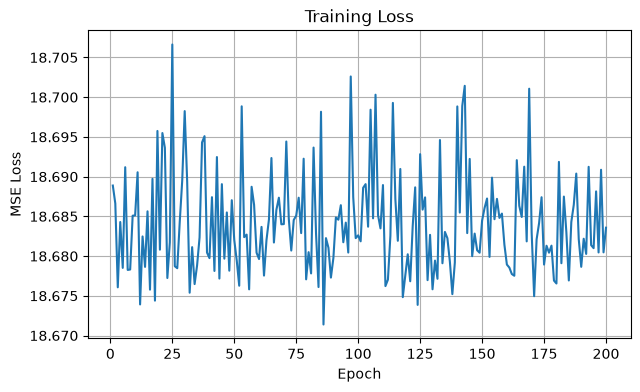

In [17]:
# loss 그래프 그리기
plt.figure(figsize=(7,4))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')
plt. grid()

In [21]:
model.eval()
with torch.no_grad() : 
    y_pred = model(x_test_scaled)

test_loss = criterion(y_pred, y_test).item()
test_mean = torch.mean(torch.abs(y_pred - y_test)).item()
test_rmean = np.sqrt(test_loss) # MSE에 제곱근을 씌워서 원래 데이터와 동일한 단위로 변환 

print(f'Test MSE : {test_loss:.3f}')
print(f'Test MAE : {test_mean:.3f} MPG')
print(f'Test RMSE : {test_rmean:.3f} MPG')

Test MSE : 19.585
Test MAE : 3.186 MPG
Test RMSE : 4.425 MPG


### Step 5. 테스트 결과 시각화 

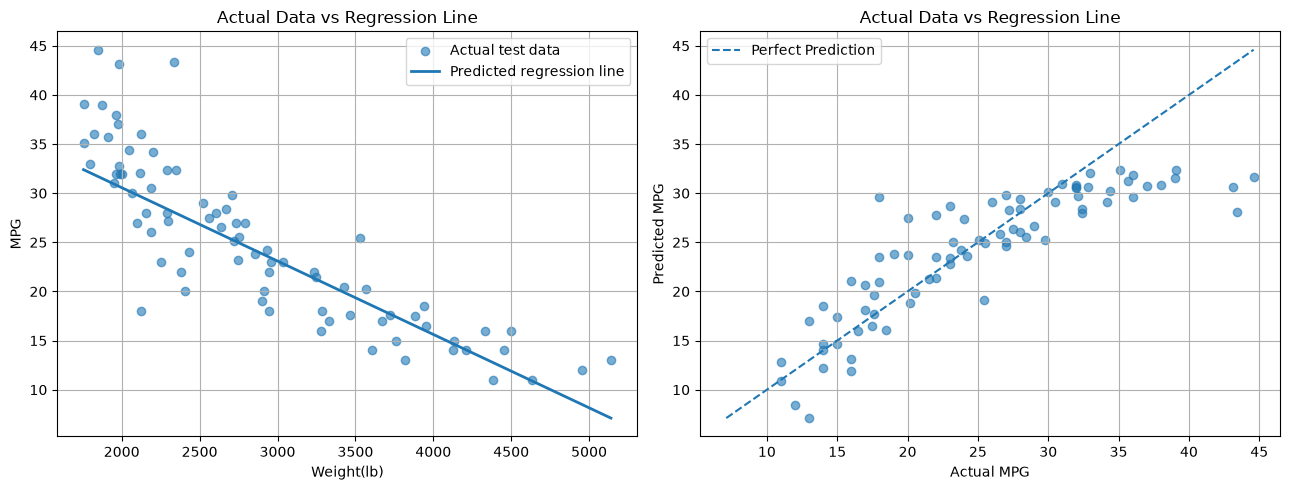

In [29]:
model.eval()
with torch.no_grad() :
    y_pred = model(x_test_scaled)

# 무게를 기준으로 정렬을 하여 회귀선을 표시
# argsort() : 정렬된 순서에 해당하는 인덱스 반환하는 함수 
sort_idx = torch.argsort(x_test.squeeze())
x_test_sorted = x_test[sort_idx]
x_test_scaled_sorted = x_test_scaled[sort_idx]
y_test_sorted = y_test[sort_idx]

with torch.no_grad() :
    y_pred_sorted = model(x_test_scaled_sorted)

fig, axes = plt.subplots(1,2,figsize = (13,5))

# 실제 테스트 데이터와 예측 회귀선
axes[0].scatter(x_test.numpy(), y_test.numpy(), alpha = 0.6, label = 'Actual test data')

axes[0].plot(x_test_sorted.numpy(), y_pred_sorted.numpy(), 
            linewidth = 2, label = 'Predicted regression line')
axes[0].set_xlabel('Weight(lb)')
axes[0].set_ylabel('MPG')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

# 테스트의 실제값과 예측값 비교 
axes[1].scatter(y_test.numpy(),y_pred.numpy(), alpha = 0.6)
min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val], [min_val, max_val], linestyle = '--', label = 'Perfect Prediction')
axes[1].set_xlabel('Actual MPG')
axes[1].set_ylabel('Predicted MPG')
axes[1].set_title('Actual Data vs Regression Line')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()